In [132]:
import os
import pandas as pd
from pathlib import Path
import gc

# Run garbage collection
gc.collect()

data_folder = Path(r"C:\Users\ps302\OneDrive\Desktop\Name_that_LLM\data\train.csv")
data_path = os.path.join(os.getcwd(), data_folder)

print(data_path)

df = pd.read_csv(data_path)
df.head()

C:\Users\ps302\OneDrive\Desktop\Name_that_LLM\data\train.csv


,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash
3,009319596f10,p073,Data science communities matter because they t...,gpt-5.6-terra
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash


In [133]:
# !pip install psycopg

In [134]:
# Applying label encoder
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df["model"] = le.fit_transform(df["model"])
df.head(5)

,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",17
1,0041ac86ee93,p073,Data science communities matter because they a...,4
2,005a19083eae,p120,"In the final twilight of time, the last embers...",6
3,009319596f10,p073,Data science communities matter because they t...,14
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",10


In [135]:
from psycopg.generators import fetch
import re
import numpy as np
import pandas as pd
import nltk
nltk.download("punkt")
from nltk.tokenize import sent_tokenize, word_tokenize

features = pd.DataFrame(index=df.index)
features["model"] = df["model"]
text_col = "text"

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ps302\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ps302\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [136]:
# Character, word, and sentence counts
features["char_count"] = df[text_col].apply(len)
features.head()

,model,char_count
0,17,1143
1,4,518
2,6,474
3,14,1724
4,10,541


In [137]:
# features.iloc[:, 1:]

In [138]:
# Words & Sentences
def get_words_and_sents(text):
        sents = sent_tokenize(text) if len(text.strip()) > 0 else [""]
        words = word_tokenize(text) if len(text.strip()) > 0 else [""]
        return len(words), len(sents), sents, words

tokenized_info = df[text_col].apply(get_words_and_sents)
features["word_count"] = tokenized_info.apply(lambda x: x[0])
features["sent_count"] = tokenized_info.apply(lambda x: x[1])

features.head()

,model,char_count,word_count,sent_count
0,17,1143,222,8
1,4,518,74,4
2,6,474,89,4
3,14,1724,263,9
4,10,541,114,4


In [139]:
# features.iloc[:, 1:]

In [140]:
# Sentence Length Mean & Variance
def sent_stats(info):
    _, num_sents, sents, _ = info
    if num_sents == 0:
        return 0.0, 0.0
    lengths = [len(s.split()) for s in sents]
    return float(np.mean(lengths)), float(np.var(lengths))

sent_metrics = tokenized_info.apply(sent_stats)
features["avg_sent_len"] = sent_metrics.apply(lambda x: x[0])
features["var_sent_len"] = sent_metrics.apply(lambda x: x[1])

features.head()

,model,char_count,word_count,sent_count,avg_sent_len,var_sent_len
0,17,1143,222,8,24.000000,91.000000
1,4,518,74,4,16.250000,10.687500
2,6,474,89,4,19.250000,17.687500
3,14,1724,263,9,24.444444,17.135802
4,10,541,114,4,24.250000,8.687500


In [141]:
# Avg Word Length
features["avg_word_len"] = features["char_count"] / (features["word_count"] + 1e-5)

features.head()

,model,char_count,word_count,sent_count,avg_sent_len,var_sent_len,avg_word_len
0,17,1143,222,8,24.000000,91.000000,5.148648
1,4,518,74,4,16.250000,10.687500,6.999999
2,6,474,89,4,19.250000,17.687500,5.325842
3,14,1724,263,9,24.444444,17.135802,6.555133
4,10,541,114,4,24.250000,8.687500,4.745614


In [142]:
# ----------------- 2. Markdown Stylometry -----------------
features["md_asterisk_count"] = df[text_col].apply(lambda x: x.count("*"))  # Bold or italics (* or **)

features.head()

,model,char_count,word_count,sent_count,avg_sent_len,var_sent_len,avg_word_len,md_asterisk_count
0,17,1143,222,8,24.000000,91.000000,5.148648,0
1,4,518,74,4,16.250000,10.687500,6.999999,0
2,6,474,89,4,19.250000,17.687500,5.325842,0
3,14,1724,263,9,24.444444,17.135802,6.555133,0
4,10,541,114,4,24.250000,8.687500,4.745614,0


In [143]:
# ----------------- 3. Punctuation Fingerprint -----------------
features["punct_colon"] = df[text_col].apply(lambda x: x.count(":"))
features["punct_semicolon"] = df[text_col].apply(lambda x: x.count(";"))
features["punct_em_dash"] = df[text_col].apply(lambda x: x.count("—") + x.count("--"))
features["punct_exclamation"] = df[text_col].apply(lambda x: x.count("!"))
features["punct_question"] = df[text_col].apply(lambda x: x.count("?"))
features["punct_comma"] = df[text_col].apply(lambda x: x.count(","))
features["punct_period"] = df[text_col].apply(lambda x: x.count("."))
features["punct_quotes"] = df[text_col].apply(lambda x: x.count('"') + x.count("'"))
features["punct_parens"] = df[text_col].apply(lambda x: x.count("(") + x.count(")"))
features["punct_brackets"] = df[text_col].apply(lambda x: x.count("[") + x.count("]"))

features.head()

,model,char_count,word_count,sent_count,avg_sent_len,var_sent_len,avg_word_len,md_asterisk_count,punct_colon,punct_semicolon,punct_em_dash,punct_exclamation,punct_question,punct_comma,punct_period,punct_quotes,punct_parens,punct_brackets
0,17,1143,222,8,24.000000,91.000000,5.148648,0,1,2,0,0,0,17,8,0,0,0
1,4,518,74,4,16.250000,10.687500,6.999999,0,0,0,0,0,0,5,4,0,0,0
2,6,474,89,4,19.250000,17.687500,5.325842,0,0,0,0,0,0,8,4,0,0,0
3,14,1724,263,9,24.444444,17.135802,6.555133,0,1,1,0,0,0,32,9,0,0,0
4,10,541,114,4,24.250000,8.687500,4.745614,0,1,0,2,0,0,8,4,0,0,0


In [144]:
# for col in features.columns:
#     print(f"{col} -> {features[col].value_counts()}")

In [145]:
# Punctuation Density (normalized by word count)
total_puncts = (features["punct_colon"] + features["punct_semicolon"] + 
                features["punct_comma"] + features["punct_period"] + features["punct_exclamation"])
features["punct_density"] = total_puncts / (features["word_count"] + 1e-5)

features.head()

,model,char_count,word_count,sent_count,avg_sent_len,var_sent_len,avg_word_len,md_asterisk_count,punct_colon,punct_semicolon,punct_em_dash,punct_exclamation,punct_question,punct_comma,punct_period,punct_quotes,punct_parens,punct_brackets,punct_density
0,17,1143,222,8,24.000000,91.000000,5.148648,0,1,2,0,0,0,17,8,0,0,0,0.126126
1,4,518,74,4,16.250000,10.687500,6.999999,0,0,0,0,0,0,5,4,0,0,0,0.121622
2,6,474,89,4,19.250000,17.687500,5.325842,0,0,0,0,0,0,8,4,0,0,0,0.134831
3,14,1724,263,9,24.444444,17.135802,6.555133,0,1,1,0,0,0,32,9,0,0,0,0.163498
4,10,541,114,4,24.250000,8.687500,4.745614,0,1,0,2,0,0,8,4,0,0,0,0.114035


In [146]:
# ----------------- 4. Capitalization & Casing -----------------
features["upper_char_count"] = df[text_col].apply(lambda x: sum(1 for c in x if c.isupper()))
features["upper_char_ratio"] = features["upper_char_count"] / (features["char_count"] + 1e-5)
features["all_caps_words"] = df[text_col].apply(lambda x: len(re.findall(r"\b[A-Z]{2,}\b", x)))
features["camel_case_count"] = df[text_col].apply(lambda x: len(re.findall(r"\b[a-z]+[A-Z][a-zA-Z]*\b", x)))

features.head()

,model,char_count,word_count,sent_count,avg_sent_len,var_sent_len,avg_word_len,md_asterisk_count,punct_colon,punct_semicolon,...,punct_comma,punct_period,punct_quotes,punct_parens,punct_brackets,punct_density,upper_char_count,upper_char_ratio,all_caps_words,camel_case_count
0,17,1143,222,8,24.000000,91.000000,5.148648,0,1,2,...,17,8,0,0,0,0.126126,10,0.008749,0,0
1,4,518,74,4,16.250000,10.687500,6.999999,0,0,0,...,5,4,0,0,0,0.121622,4,0.007722,0,0
2,6,474,89,4,19.250000,17.687500,5.325842,0,0,0,...,8,4,0,0,0,0.134831,4,0.008439,0,0
3,14,1724,263,9,24.444444,17.135802,6.555133,0,1,1,...,32,9,0,0,0,0.163498,9,0.005220,0,0
4,10,541,114,4,24.250000,8.687500,4.745614,0,1,0,...,8,4,0,0,0,0.114035,4,0.007394,0,0


In [147]:
# ----------------- 5. Lexical Diversity (Type-Token Ratio) -----------------
def type_token_ratio(info):
    num_words, _, _, words = info
    if num_words == 0:
        return 0.0
    unique_words = set(w.lower() for w in words if w.isalnum())
    return len(unique_words) / (num_words + 1e-5)

features["lexical_diversity_ttr"] = tokenized_info.apply(type_token_ratio)

features.head()

,model,char_count,word_count,sent_count,avg_sent_len,var_sent_len,avg_word_len,md_asterisk_count,punct_colon,punct_semicolon,...,punct_period,punct_quotes,punct_parens,punct_brackets,punct_density,upper_char_count,upper_char_ratio,all_caps_words,camel_case_count,lexical_diversity_ttr
0,17,1143,222,8,24.000000,91.000000,5.148648,0,1,2,...,8,0,0,0,0.126126,10,0.008749,0,0,0.617117
1,4,518,74,4,16.250000,10.687500,6.999999,0,0,0,...,4,0,0,0,0.121622,4,0.007722,0,0,0.783784
2,6,474,89,4,19.250000,17.687500,5.325842,0,0,0,...,4,0,0,0,0.134831,4,0.008439,0,0,0.707865
3,14,1724,263,9,24.444444,17.135802,6.555133,0,1,1,...,9,0,0,0,0.163498,9,0.005220,0,0,0.669201
4,10,541,114,4,24.250000,8.687500,4.745614,0,1,0,...,4,0,0,0,0.114035,4,0.007394,0,0,0.684210


In [148]:
# Digits / Numbers presence
features["digit_count"] = df[text_col].apply(lambda x: sum(1 for c in x if c.isdigit()))
features["digit_ratio"] = features["digit_count"] / (features["char_count"] + 1e-5)
features.head()

,model,char_count,word_count,sent_count,avg_sent_len,var_sent_len,avg_word_len,md_asterisk_count,punct_colon,punct_semicolon,...,punct_parens,punct_brackets,punct_density,upper_char_count,upper_char_ratio,all_caps_words,camel_case_count,lexical_diversity_ttr,digit_count,digit_ratio
0,17,1143,222,8,24.000000,91.000000,5.148648,0,1,2,...,0,0,0.126126,10,0.008749,0,0,0.617117,0,0.0
1,4,518,74,4,16.250000,10.687500,6.999999,0,0,0,...,0,0,0.121622,4,0.007722,0,0,0.783784,0,0.0
2,6,474,89,4,19.250000,17.687500,5.325842,0,0,0,...,0,0,0.134831,4,0.008439,0,0,0.707865,0,0.0
3,14,1724,263,9,24.444444,17.135802,6.555133,0,1,1,...,0,0,0.163498,9,0.005220,0,0,0.669201,0,0.0
4,10,541,114,4,24.250000,8.687500,4.745614,0,1,0,...,0,0,0.114035,4,0.007394,0,0,0.684210,0,0.0


In [149]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

#  Train-Test Split (stratified)
df_train, df_test = train_test_split(features, test_size=0.2, random_state=42, stratify=features["model"])
y_train = df_train["model"].values
y_test = df_test["model"].values


In [150]:
X_train_pre = df_train.iloc[:, 1:]
X_test_pre = df_test.iloc[:, 1:]

X_train_pre.shape, X_test_pre.shape
# X_train.head()

((2159, 25), (540, 25))

In [151]:
encoder = StandardScaler()
X_train = encoder.fit_transform(X_train_pre)
X_test = encoder.transform(X_test_pre)
X_train.shape, X_test.shape
X_train

array([[-0.67748689, -0.9011098 , -0.86313925, ...,  2.16808601,
        -0.27476085, -0.27539568],
       [-1.02243627, -1.11143533, -1.32486315, ...,  0.9537711 ,
        -0.27476085, -0.27539568],
       [ 1.38424906,  1.44251746,  0.98375633, ..., -0.81265661,
        -0.27476085, -0.27539568],
       ...,
       [-0.44398269, -0.46543551, -0.40141535, ...,  0.54076443,
        -0.27476085, -0.27539568],
       [-1.32227689, -1.26166784, -1.32486315, ...,  2.29210031,
        -0.27476085, -0.27539568],
       [-1.08346578, -1.00627257, -1.32486315, ...,  1.30333501,
        -0.27476085, -0.27539568]], shape=(2159, 25))

In [164]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, recall_score

# Initialize regularized XGBoost
xgb = XGBClassifier(
    objective="multi:softprob",
    num_class=len(le.classes_),
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=4,              # Shallow depth to prevent overfit
    subsample=0.8,
    colsample_bytree=0.8,
    # early_stopping_rounds=25,
    eval_metric="mlogloss",
    random_state=42,
    tree_method="hist",
    device="cuda"             # Use "cpu" if no GPU available
)

xgb.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_test, y_test)],
    verbose=25
)

y_pred = xgb.predict(X_test)
print(f"\n--- Sirf Stylometric Features ka Result ---")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")
print(f"Recall Score (Macro): {recall_score(y_test, y_pred, average='macro'):.4f}")


[0]	validation_0-mlogloss:2.84369	validation_1-mlogloss:2.86037


c:\Users\ps302\anaconda3\envs\genai\lib\site-packages\xgboost\training.py:200: UserWarning: [17:11:27] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:53: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\ps302\anaconda3\envs\genai\lib\site-packages\xgboost\training.py:200: UserWarning: [17:11:27] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:207: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)


[25]	validation_0-mlogloss:2.15372	validation_1-mlogloss:2.48055
[50]	validation_0-mlogloss:1.80816	validation_1-mlogloss:2.33721
[75]	validation_0-mlogloss:1.57934	validation_1-mlogloss:2.27911
[100]	validation_0-mlogloss:1.40747	validation_1-mlogloss:2.25653
[125]	validation_0-mlogloss:1.26703	validation_1-mlogloss:2.25060
[150]	validation_0-mlogloss:1.14631	validation_1-mlogloss:2.25269
[175]	validation_0-mlogloss:1.03978	validation_1-mlogloss:2.25971
[200]	validation_0-mlogloss:0.94421	validation_1-mlogloss:2.26592
[225]	validation_0-mlogloss:0.85867	validation_1-mlogloss:2.27519
[250]	validation_0-mlogloss:0.78455	validation_1-mlogloss:2.28486
[275]	validation_0-mlogloss:0.71528	validation_1-mlogloss:2.29749
[300]	validation_0-mlogloss:0.65229	validation_1-mlogloss:2.30882
[325]	validation_0-mlogloss:0.59500	validation_1-mlogloss:2.32338
[350]	validation_0-mlogloss:0.54264	validation_1-mlogloss:2.34005
[375]	validation_0-mlogloss:0.49621	validation_1-mlogloss:2.35295
[400]	validat

In [169]:
# %pip install optuna
import optuna
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, recall_score, log_loss

# Warning logs clean rakhne ke liye
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    # Search Space for Tuning
    params = {
        "objective": "multi:softprob",
        "num_class": len(set(y_train)),
        "eval_metric": "mlogloss",
        "random_state": 42,
        "n_estimators": 1000,                     # Zyada trees rakhein aur early stop par depend karein
        "tree_method": "hist",
        "device": "cpu",                          # Warning avoid karne ke liye explicitly "cpu"
        
        # Tunable Hyperparameters
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.08, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 6),                     # Shallow trees for less overfit
        "min_child_weight": trial.suggest_int("min_child_weight", 2, 10),      # Prevents learning noisy patterns
        "subsample": trial.suggest_float("subsample", 0.6, 0.9),               # Row sampling
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 0.8), # Feature sampling
        
        # Regularization (Crucial to stop val_loss from rising)
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),   # L1 Regularization
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-2, 10.0, log=True),  # L2 Regularization
    }
    
    model = XGBClassifier(**params, early_stopping_rounds=30)
    
    # Fit model with early stopping
    model.fit(
        X_train, y_train,
        eval_set=[(X_test, y_test)],
        verbose=False
    )
    
    # Predict probabilities for log loss evaluation
    y_proba = model.predict_proba(X_test)
    val_loss = log_loss(y_test, y_proba)
    
    return val_loss

# Run 30 trials (takes about 1-2 minutes on CPU)
print("Starting Hyperparameter Tuning with Optuna...")
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=30, show_progress_bar=True)

print("\n" + "="*50)
print(f"Best Validation Loss: {study.best_value:.4f}")
print("Best Parameters:")
for k, v in study.best_params.items():
    print(f"  {k}: {v}")
print("="*50)


Starting Hyperparameter Tuning with Optuna...


Best trial: 25. Best value: 2.22168: 100%|██████████| 30/30 [03:13<00:00,  6.46s/it]


Best Validation Loss: 2.2217
Best Parameters:
  learning_rate: 0.016233718295725202
  max_depth: 3
  min_child_weight: 6
  subsample: 0.7994882183131978
  colsample_bytree: 0.618332389966442
  reg_alpha: 0.24050481000177834
  reg_lambda: 0.7761466043476581


In [ ]:
best_params = study.best_params

# Best parameters se final model train karein
best_xgb = XGBClassifier(
    objective="multi:softprob",
    num_class=len(set(y_train)),
    eval_metric="mlogloss",
    random_state=42,
    n_estimators=1000,
    tree_method="hist",
    device="cpu",
    early_stopping_rounds=40,
    **best_params
)

best_xgb.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_test, y_test)],
    verbose=25
)

# Predictions
y_pred_best = best_xgb.predict(X_test)

print("\n--- Final Tuned Model Results ---")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_best):.4f}")
print(f"Recall Score (Macro): {recall_score(y_test, y_pred_best, average='macro'):.4f}")
print(f"Best Iteration Stopped At: {best_xgb.best_iteration}")


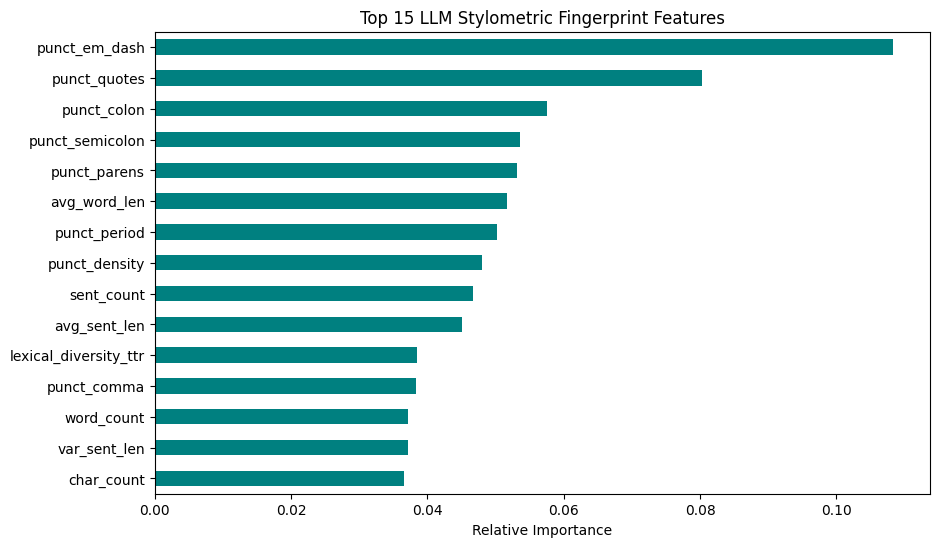

In [153]:
import matplotlib.pyplot as plt

importance = pd.Series(xgb.feature_importances_, index=X_train_pre.columns)
importance.sort_values(ascending=False).head(15).plot(kind="barh", figsize=(10, 6), color="teal")
plt.title("Top 15 LLM Stylometric Fingerprint Features")
plt.xlabel("Relative Importance")
plt.gca().invert_yaxis()
plt.show()


In [154]:
# word_vec = TfidfVectorizer(ngram_range=(1, 2), max_features=20000, sublinear_tf=True)
# char_vec = TfidfVectorizer(analyzer='char', ngram_range=(3, 5), max_features=40000, sublinear_tf=True)

# # Fit on text
# X_train_w = word_vec.fit_transform(df_train["text"]).toarray()
# X_test_w = word_vec.transform(df_test["text"]).toarray()

# X_train_c = char_vec.fit_transform(df_train["text"]).toarray()
# X_test_c = char_vec.transform(df_test["text"]).toarray()

# X_train_num = df_train[["num_chars", "num_words", "num_sents"]].values
# X_test_num = df_test[["num_chars", "num_words", "num_sents"]].values

In [155]:
# from sklearn.preprocessing import MinMaxScaler
# scaler = MinMaxScaler()
# X_train_num_scaled = scaler.fit_transform(X_train_num)
# X_test_num_scaled = scaler.transform(X_test_num)
# X_train = np.hstack((X_train_w, X_train_c, X_train_num_scaled))
# X_test = np.hstack((X_test_w, X_test_c, X_test_num_scaled))
# print(X_train.shape,X_test.shape)


In [ ]:
from sklearn.linear_model import LogisticRegression
clf = LogisticRegression(max_iter=1000, C=2.0, verbose=1)

clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")
print(f"Recall Score: {recall_score(y_test, y_pred, average='macro'):.4f}")
# print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_pred)}")


Accuracy Score: 0.2630
Recall Score: 0.2630


[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s finished


In [157]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix

rf = RandomForestClassifier(
    n_estimators=200,      # Number of trees
    max_depth=15,          # Overfitting control karne ke liye
    random_state=42,
    n_jobs=-1,             # Saare CPU cores use karne ke liye (fast execution)
    verbose=1              # Training progress dekhne ke liye
)

rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")
print(f"Recall Score: {recall_score(y_test, y_pred, average='macro'):.4f}")
# print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_pred)}")


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=-1)]: Done  18 tasks      | elapsed:    0.0s


Accuracy Score: 0.2389
Recall Score: 0.2389


[Parallel(n_jobs=-1)]: Done 168 tasks      | elapsed:    0.2s
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:    0.2s finished
[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  18 tasks      | elapsed:    0.0s
[Parallel(n_jobs=16)]: Done 168 tasks      | elapsed:    0.0s
[Parallel(n_jobs=16)]: Done 200 out of 200 | elapsed:    0.0s finished


In [158]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score

gnb = GaussianNB()
gnb.fit(X_train, y_train)
y_pred = gnb.predict(X_test)

print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")
print(f"Recall Score: {recall_score(y_test, y_pred,  average='macro'):.4f}")
# print(f"Confusion Metrics: {confusion_matrix(y_test, y_pred)}")

Accuracy Score: 0.1074
Recall Score: 0.1074


In [159]:
# from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
# from sklearn.metrics import accuracy_score, confusion_matrix, recall_score

# mnb = MultinomialNB()
# mnb.fit(X_train, y_train)
# y_pred = mnb.predict(X_test)

# print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")
# print(f"Recall Score: {recall_score(y_test, y_pred,  average='macro'):.4f}")
# # print(f"Confusion Metrics: {confusion_matrix(y_test, y_pred)}")

In [160]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score

bnb = BernoulliNB()
bnb.fit(X_train, y_train)
y_pred = bnb.predict(X_test)

print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")
print(f"Recall Score: {recall_score(y_test, y_pred,  average='macro'):.4f}")
# print(f"Confusion Metrics: \n {confusion_matrix(y_test, y_pred)}")

Accuracy Score: 0.1630
Recall Score: 0.1630


In [161]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix

# 'linear' kernel is usually best and fastest for text/NLP features (TF-IDF, Bag of Words)
# For non-linear, use kernel='rbf' (default)
svm = SVC(kernel="linear", random_state=42)
svm.fit(X_train, y_train)
y_pred = svm.predict(X_test)

print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")
print(f"Recall Score: {recall_score(y_test, y_pred, average='macro'):.4f}")
# print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_pred)}")


Accuracy Score: 0.2611
Recall Score: 0.2611


In [162]:
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix

lgb = LGBMClassifier(
    objective="multiclass",
    n_estimators=100,
    learning_rate=0.08,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,

    device_type="gpu",  # GPU via OpenCL
    max_bin=63,
    verbosity=1
)

lgb.fit(
    X_train,
    y_train,
    eval_set=[(X_train, y_train), (X_test, y_test)],
    eval_metric="multi_logloss",
    callbacks=[
        __import__("lightgbm").log_evaluation(period=1)
    ]
)

y_pred = lgb.predict(X_test)

print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")
print(f"Recall Score: {recall_score(y_test, y_pred, average='macro'):.4f}")
print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_pred)}")

[LightGBM] [Info] This is the GPU trainer!!
[LightGBM] [Info] Total Bins 723
[LightGBM] [Info] Number of data points in the train set: 2159, number of used features: 21
[LightGBM] [Info] Using GPU Device: Intel(R) Iris(R) Xe Graphics, Vendor: Intel(R) Corporation
[LightGBM] [Info] Compiling OpenCL Kernel with 64 bins...
[LightGBM] [Info] GPU programs have been built
[LightGBM] [Info] Size of histogram bin entry: 8
[LightGBM] [Info] 16 dense feature groups (0.03 MB) transferred to GPU in 0.002698 secs. 1 sparse feature groups
[LightGBM] [Info] Start training from score -2.898277
[LightGBM] [Info] Start training from score -2.889909
[LightGBM] [Info] Start training from score -2.889909
[LightGBM] [Info] Start training from score -2.889909
[LightGBM] [Info] Start training from score -2.889909
[LightGBM] [Info] Start training from score -2.889909
[LightGBM] [Info] Start training from score -2.889909
[LightGBM] [Info] Start training from score -2.889909
[LightGBM] [Info] Start training from

c:\Users\ps302\anaconda3\envs\genai\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
